In [12]:
import pandas as pd
import numpy as np

final_df = pd.read_csv('Final_Dataset.csv')

df = final_df.copy()

final_df.head()

,Unnamed: 0,Player,Position,Team,Comp,Age,MP,Min,Goals,Ast,...,Shots Blocked,Interceptions,Clearances,Errors,Dribbles Successful,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values
0,0,Antonee Robinson,DF,fulham,eng Premier League,27-175,23,2070,0,9,...,13,44,75,0,25,7034,27,96,61.4,28000000.0
1,1,Nathan Collins,DF,brentford,eng Premier League,23-275,23,2070,2,1,...,12,20,130,2,5,7142,10,105,65.2,28000000.0
2,2,Illia Zabarnyi,DF,bournemouth,eng Premier League,22-151,23,2070,0,0,...,7,23,117,2,4,7181,10,109,67.9,38000000.0
3,3,Bryan Mbeumo,FW,brentford,eng Premier League,25-176,23,2064,14,3,...,41,9,34,0,29,2570,65,95,29.7,50000000.0
4,4,Moises Caicedo,MF,chelsea,eng Premier League,23-089,23,2035,1,2,...,12,33,36,0,14,5574,23,137,70.6,80000000.0


In [13]:
# # Calculate total market value of each team
# df['Team_Total_Value'] = df.groupby('Team')['Values'].transform('sum')

# # Assign team ratings from 1 to 5
# df['Value Team'] = (
#     pd.qcut(
#         df['Team_Total_Value'].rank(method='dense'),
#         q=5,
#         labels=False
#     ) + 1
# ).astype(int)

# df.head()

In [14]:
# Remove unnecessary columns
df.drop(
    columns=['Player', 'Team', 'Comp'],
    inplace=True,
    errors='ignore'
)

# Process Age
df['Age'] = df['Age'].astype(str).str.split('-').str[0].astype(int)

# Convert Position into dummy variables
position_dummies = df['Position'].str.get_dummies(sep=',')

position_dummies = position_dummies.reindex(
    columns=['DF', 'MF', 'FW'],
    fill_value=0
)

# Combine position columns with original dataset
df = pd.concat([df, position_dummies], axis=1)

# Remove original Position column
df.drop(columns=['Position'], inplace=True, errors='ignore')

# Display processed dataset
df.head()

,Unnamed: 0,Age,MP,Min,Goals,Ast,G+A,xG,xA,SoT%,...,Errors,Dribbles Successful,Dribble Distance,Mistakes,Ball Recoveries,Air Duels Won%,Values,DF,MF,FW
0,0,27,23,2070,0,9,9,0.6,3.0,15.4,...,0,25,7034,27,96,61.4,28000000.0,1,0,0
1,1,23,23,2070,2,1,3,2.2,1.1,41.7,...,2,5,7142,10,105,65.2,28000000.0,1,0,0
2,2,22,23,2070,0,0,0,0.8,0.4,0.0,...,2,4,7181,10,109,67.9,38000000.0,1,0,0
3,3,25,23,2064,14,3,17,7.7,5.1,53.7,...,0,29,2570,65,95,29.7,50000000.0,0,0,1
4,4,23,23,2035,1,2,3,0.6,1.7,16.7,...,0,14,5574,23,137,70.6,80000000.0,0,1,0


In [18]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=['Values', 'Unnamed: 0'], errors='ignore')
y = df['Values']

# Split dataset into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

Training data: (1591, 30)
Validation data: (398, 30)


In [19]:
from sklearn.impute import SimpleImputer

# Create imputer
imputer = SimpleImputer(strategy='mean')

# Fit on training data and transform
X_train = imputer.fit_transform(X_train)

# Transform validation data using training mean
X_val = imputer.transform(X_val)

print("Missing values in training:", np.isnan(X_train).sum())
print("Missing values in validation:", np.isnan(X_val).sum())

Missing values in training: 0
Missing values in validation: 0


In [22]:
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation data
X_val_scaled = scaler.transform(X_val)

print("Training shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)


Training shape: (1591, 30)
Validation shape: (398, 30)


In [23]:
from sklearn.decomposition import PCA

# Initialize PCA
pca = PCA(n_components=0.99)

# Fit PCA on training data
X_train_pca = pca.fit_transform(X_train_scaled)

# Transform validation data
X_val_pca = pca.transform(X_val_scaled)

# Display results
print("Original number of features:", X_train_scaled.shape[1])
print("Number of principal components:", X_train_pca.shape[1])

print("Explained variance ratio:", pca.explained_variance_ratio_.sum())

Original number of features: 30
Number of principal components: 24
Explained variance ratio: 0.9903220295145425


In [24]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Initialize model
model = GradientBoostingRegressor(random_state=42)

# Train model using PCA-transformed training data
model.fit(X_train_pca, y_train)

# Predictions
y_train_pred = model.predict(X_train_pca)
y_val_pred = model.predict(X_val_pca)

# Evaluate model
print("Training R2:", r2_score(y_train, y_train_pred))
print("Validation R2:", r2_score(y_val, y_val_pred))

print("Training MAE:", mean_absolute_error(y_train, y_train_pred))
print("Validation MAE:", mean_absolute_error(y_val, y_val_pred))

print("Validation RMSE:", np.sqrt(mean_squared_error(y_val, y_val_pred)))

Training R2: 0.7937063910851534
Validation R2: 0.427641220881691
Training MAE: 6474348.429473839
Validation MAE: 8639124.336977111
Validation RMSE: 12801223.513370309


In [25]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# Initialize model
gb = GradientBoostingRegressor(random_state=42)

# Define hyperparameter ranges
param_dist = {
    'n_estimators': randint(100, 800),
    'learning_rate': uniform(0.01, 0.09),
    'max_depth': randint(1, 5),
    'min_samples_split': randint(5, 30),
    'min_samples_leaf': randint(5, 20),
    'subsample': uniform(0.7, 0.3),
    'max_features': ['sqrt', 'log2']
}

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_dist,
    n_iter=50,
    scoring='r2',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train using PCA-transformed data
random_search.fit(X_train_pca, y_train)

# Get best model
best_model = random_search.best_estimator_

# Predictions
y_train_pred = best_model.predict(X_train_pca)
y_val_pred = best_model.predict(X_val_pca)

# Results
from sklearn.metrics import r2_score, mean_absolute_error

print("Best Parameters:", random_search.best_params_)
print("Best CV R2:", random_search.best_score_)
print("Training R2:", r2_score(y_train, y_train_pred))
print("Validation R2:", r2_score(y_val, y_val_pred))
print("Training MAE:", mean_absolute_error(y_train, y_train_pred))
print("Validation MAE:", mean_absolute_error(y_val, y_val_pred))

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters: {'learning_rate': np.float64(0.06226179592928092), 'max_depth': 4, 'max_features': 'log2', 'min_samples_leaf': 13, 'min_samples_split': 7, 'n_estimators': 252, 'subsample': np.float64(0.7015184751538656)}
Best CV R2: 0.4333783228698923
Training R2: 0.802487807229278
Validation R2: 0.41774969926092576
Training MAE: 6017299.555814954
Validation MAE: 8617905.643190732


Total Components: 24
Total Features Before PCA: 30
Variance Retained: 0.9903220295145426


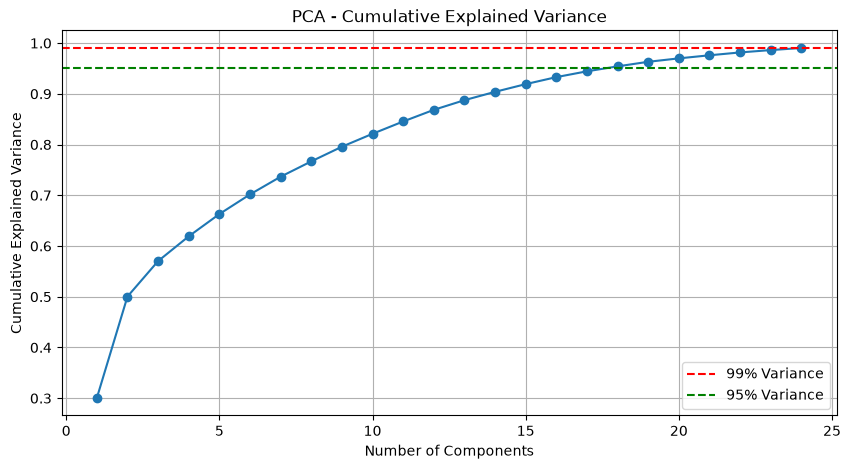

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Display PCA information
print("Total Components:", pca.n_components_)
print("Total Features Before PCA:", X_train_scaled.shape[1])
print("Variance Retained:", cumulative_variance[-1])

# Plot cumulative explained variance
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(y=0.99, color='red', linestyle='--', label='99% Variance')
plt.axhline(y=0.95, color='green', linestyle='--', label='95% Variance')

plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance')
plt.legend()
plt.grid()
plt.show()

In [ ]:
X_train_pca = pca.fit_transform(X_train_scaled)

# Train model
model = GradientBoostingRegressor(random_state=42)
model.fit(X_train_pca, y_train)

# Training R2 Score
y_train_pred = model.predict(X_train_pca)

print("Training R2 Score:", r2_score(y_train, y_train_pred))

Training R2 Score: 0.7943942321734241


In [ ]:

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error
from scipy.stats import randint, uniform

# Define the model
gb = GradientBoostingRegressor(random_state=42)

# Define hyperparameter ranges
param_dist = {
    'n_estimators': randint(100, 1000),
    'learning_rate': uniform(0.01, 0.19),
    'max_depth': randint(2, 8),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10),
    'subsample': uniform(0.7, 0.3),
    'max_features': ['sqrt', 'log2', None]
}

# Randomized Search
random_search = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_dist,
    n_iter=50,
    scoring='r2',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train the search
random_search.fit(X_train, y_train)

# Get best model
best_model = random_search.best_estimator_

# Training predictions
y_train_pred = best_model.predict(X_train)

# Validation predictions
y_val_pred = best_model.predict(X_val)

# Results
print("Best Parameters:", random_search.best_params_)
print("Best CV R2:", random_search.best_score_)
print("Training R2:", r2_score(y_train, y_train_pred))
print("Validation R2:", r2_score(y_val, y_val_pred))
print("Validation MAE:", mean_absolute_error(y_val, y_val_pred))


Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters: {'learning_rate': np.float64(0.05034443102887247), 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 13, 'n_estimators': 413, 'subsample': np.float64(0.8574269294896713)}
Best CV R2: 0.4764579434562829
Training R2: 0.9515314064338781
Validation R2: 0.37828054076895534
Validation MAE: 8605547.12822542
